# Day 09 — Healthcare Resource Demand Forecast: analysis

**Question.** How many respiratory ED visits should a hospital system expect over the next 8 weeks, with what uncertainty, and what staffing posture does each forecast level imply?

**Sources.** CDC NSSP Emergency Department Visits — COVID-19, Flu, RSV (`vutn-jzwm`, data.cdc.gov) and HHS hospital bed capacity by state timeseries (`g62h-syeh`, healthdata.gov). Both are US federal public-domain data. Full provenance, fetch date (2026-11-13) and row counts (NSSP 25,116; bed 81,713) are in `data/README.md` and `data/processed/data_source.json`.

**Scope.** Analytical exercise on public aggregate surveillance data. **Not a clinical or operational decision tool.** The bed series ends 2024-04-27 and is a historical record, not current capacity. Staffing uplifts are **planning assumptions**, not measured data.


In [1]:
"""Setup: resolve the project root from this notebook's own location."""
import json
import sys
from pathlib import Path

import pandas as pd

def _find_root() -> Path:
    here = Path().resolve()  # nbconvert runs with cwd = notebook dir
    # Walk up from this file's directory until data/processed exists.
    candidates = [Path.cwd(), Path(__file__).parent if "__file__" in globals() else Path.cwd()]
    for start in candidates:
        for parent in [start, *start.parents]:
            if (parent / "data" / "processed" / "national_combined.csv").exists():
                return parent
    raise FileNotFoundError("could not find data/processed/national_combined.csv from the notebook location")

ROOT = _find_root()
sys.path.insert(0, str(ROOT))
PROCESSED = ROOT / "data" / "processed"

record = json.loads((PROCESSED / "data_source.json").read_text())
national = pd.read_csv(PROCESSED / "national_combined.csv", parse_dates=["week_end"])
states = pd.read_csv(PROCESSED / "state_combined.csv", parse_dates=["week_end"])
bed = pd.read_csv(PROCESSED / "bed_utilisation.csv", parse_dates=["week_end"])
forecast = pd.read_csv(PROCESSED / "forecast.csv", parse_dates=["week_end"])
backtest = pd.read_csv(PROCESSED / "backtest.csv")
bands = pd.read_csv(PROCESSED / "band_history.csv", parse_dates=["week_end"])
print(f"root: {ROOT}")
print(f"national series: {len(national)} weeks, {national['week_end'].min().date()} -> {national['week_end'].max().date()}")
print(f"bed series: {len(bed)} weeks, {bed['week_end'].min().date()} -> {bed['week_end'].max().date()}")
print(f"data source: {record['source']}, synthetic={record['synthetic']}")


root: /home/hatch/workspace/goals/60-day-data-ai-portfolio/day-09-healthcare-resource-demand-forecast
national series: 161 weeks, 2023-10-07 -> 2026-10-31
bed series: 226 weeks, 2020-01-04 -> 2024-04-27
data source: live, synthetic=False


## EDA — the series, the seasons, and the NULLs

- **National series:** 161 weeks, 2023-10-07 → 2026-10-31, one Combined value per week (COVID-19% + Influenza% + RSV%; there is no Combined value in the source data — the sum is valid because all three share the denominator *all ED visits*).
- **Seasonality is extreme:** mean Combined % is 6.22% in winter (Dec–Feb) vs 1.08% in summer (Jun–Aug). The overall mean is 2.6%, median 1.6%.
- **Influenza drives the winter peaks:** max flu 8.6%, max COVID-19 3.5%, max RSV 1.1%. The observed Combined maximum is **10.4%** (week ending 2023-12-30); the 2024–25 winter peaked at 10.0% (2025-02-01).
- **NULL audit:** 72 rows (0.29%) have NULL `percent_visits` — treated as missing, never 0. All 72 are recent reporting gaps: Iowa has reported nothing since 2026-07-04 (54 rows = 18 weeks × 3 pathogens), Delaware and Georgia nothing since 2026-10-17 (9 rows each). **No national week is affected** (0 of 161).


In [2]:
latest = national.iloc[-1]
print(f"Latest week ({latest['week_end'].date()}): COVID-19 {latest['covid_pct']:.1f}%, "
      f"Influenza {latest['flu_pct']:.1f}%, RSV {latest['rsv_pct']:.1f}% -> Combined {latest['combined_pct']:.1f}%")
print("\nPer-pathogen means (pp):")
print(national[["covid_pct", "flu_pct", "rsv_pct", "combined_pct"]].mean().round(2).to_string())
national["season"] = national["week_end"].dt.month.map(
    lambda m: "Winter" if m in (12, 1, 2) else "Spring" if m in (3, 4, 5)
    else "Summer" if m in (6, 7, 8) else "Autumn"
)
print("\nMean Combined % by season:")
print(national.groupby("season")["combined_pct"].mean().round(2).to_string())
print(f"\nObserved max Combined: {national['combined_pct'].max():.1f}% "
      f"({national.loc[national['combined_pct'].idxmax(), 'week_end'].date()})")
print(f"Observed min Combined: {national['combined_pct'].min():.1f}% "
      f"({national.loc[national['combined_pct'].idxmin(), 'week_end'].date()})")
audit = record["null_audit"]
print(f"\nNULL audit: {audit['n_null_percent_visits']} rows "
      f"({audit['null_share'] * 100:.2f}%); geographies: {sorted(audit['null_by_geography'])}; "
      f"national weeks affected: {audit['n_national_weeks_affected']}")
print(f"Iowa missing since: {audit['null_by_geography']['Iowa']['weeks'][0]} "
      f"({audit['null_by_geography']['Iowa']['n_rows']} rows)")


Latest week (2026-10-31): COVID-19 0.5%, Influenza 1.7%, RSV 0.1% -> Combined 2.3%

Per-pathogen means (pp):
covid_pct       0.89
flu_pct         1.46
rsv_pct         0.24
combined_pct    2.60

Mean Combined % by season:
season
Autumn    1.61
Spring    1.74
Summer    1.08
Winter    6.22

Observed max Combined: 10.4% (2023-12-30)
Observed min Combined: 0.2% (2026-06-13)

NULL audit: 72 rows (0.29%); geographies: ['Delaware', 'Georgia', 'Iowa']; national weeks affected: 0
Iowa missing since: 2026-07-04 (54 rows)


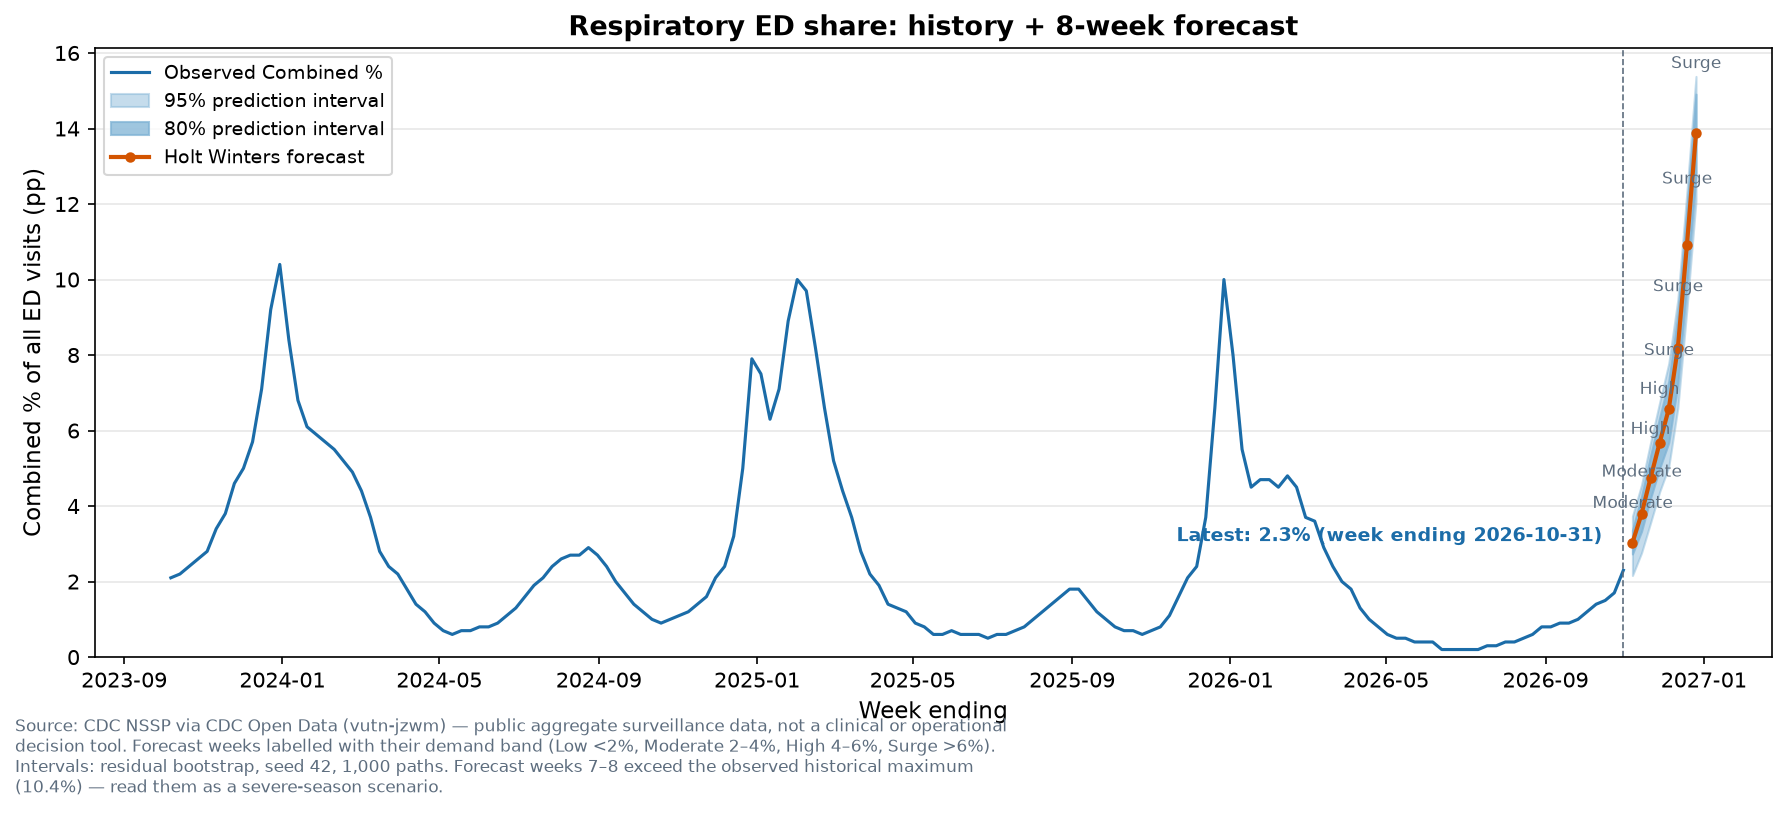

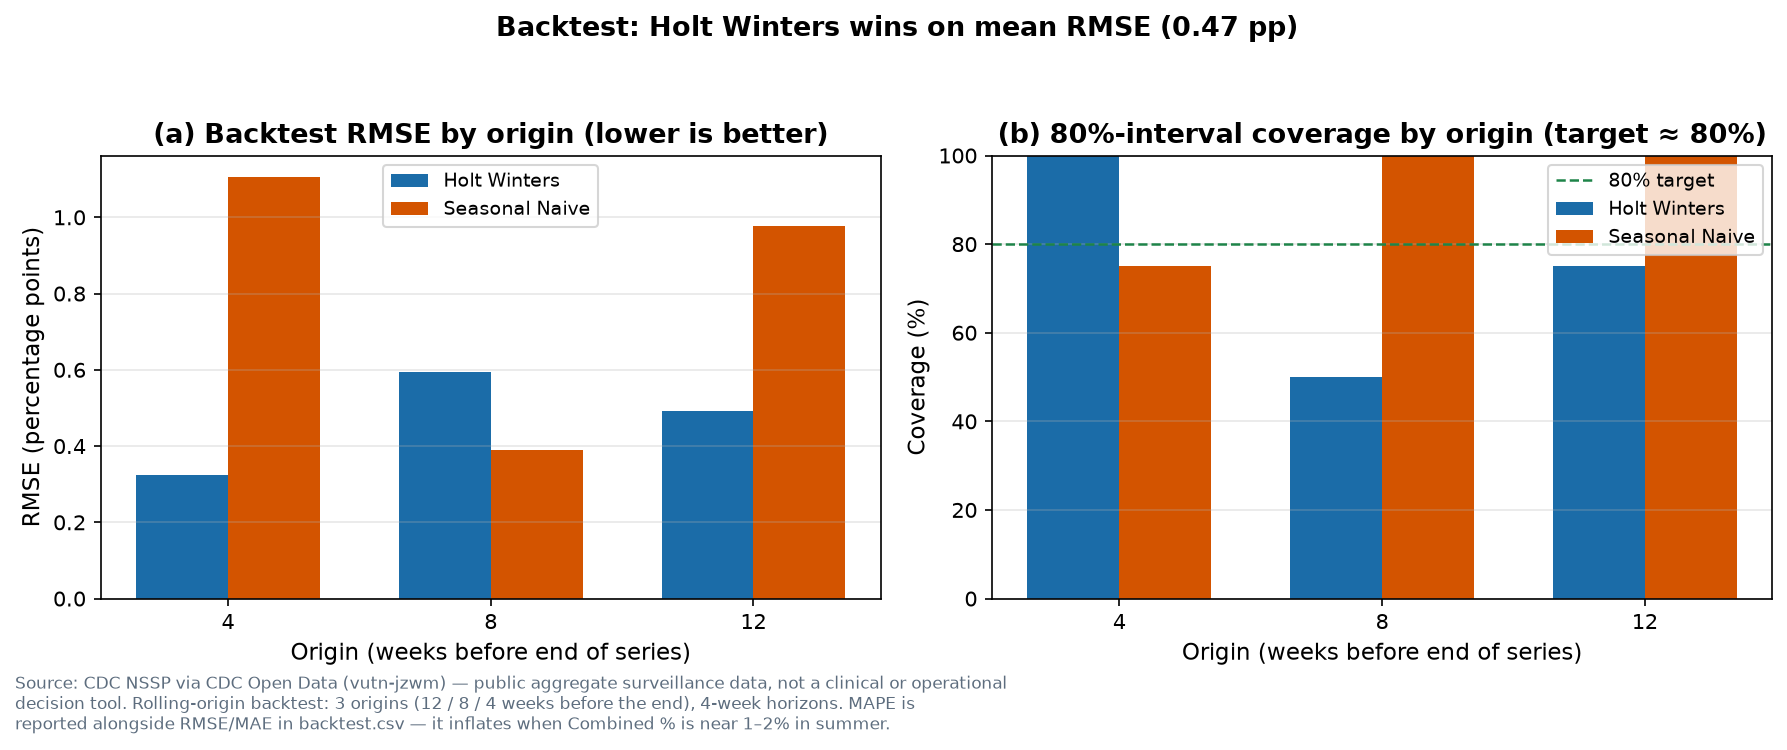

In [3]:
from IPython.display import Image, display

display(Image(str(ROOT / "outputs" / "charts" / "01_forecast.png")))
display(Image(str(ROOT / "outputs" / "charts" / "02_backtest.png")))


## Q1 — How many respiratory ED visits over the next 8 weeks, and with what uncertainty?

**Published forecast (Holt-Winters, lowest mean backtest RMSE):** Combined % rises from **3.03%** (week ending 2026-11-07) to **13.87%** (week ending 2026-12-26), with bands Moderate, Moderate, High, High, Surge, Surge, Surge, Surge. The 80% interval on the final week is 12.76–14.91%; the 95% interval is 12.08–15.38%.

Two things to read into that number before trusting it. First, the season is already running hot: influenza is at 1.7% on 2026-10-31 — 73.9% of the Combined 2.3% — versus 0.3% on the same week last year (2025-11-01), and last winter rose from 2.4% to 10.0% in eight weeks. Second, the forecast's final two weeks **exceed the observed historical maximum of 10.4%**: the additive-trend model extrapolates the steep autumn rise, so the outer weeks are a severe-season scenario, not a prediction to plan rosters on alone. The intervals widen accordingly (95% width grows from 1.57 pp in week 1 to 3.30 pp in week 8).


In [4]:
print("8-week published forecast (Holt-Winters):")
print(forecast.to_string(index=False))
print(f"\nLatest observed week: {latest['week_end'].date()} Combined {latest['combined_pct']:.1f}% "
      f"(flu {latest['flu_pct']:.1f}% = {latest['flu_pct'] / latest['combined_pct'] * 100:.1f}% of Combined)")
same_week_last_year = national[national["week_end"] == "2025-11-01"].iloc[0]
print(f"Same week last year (2025-11-01): flu {same_week_last_year['flu_pct']:.1f}%, "
      f"Combined {same_week_last_year['combined_pct']:.1f}%")
print(f"Final forecast week exceeds observed max "
      f"({record['forecast']['observed_max_combined_pct']:.1f}%): "
      f"{forecast['forecast_pct'].iloc[-1]:.2f}% > 10.4% -> treat as a severe-season scenario")
print(f"95% interval width: week 1 = {forecast['hi_95'].iloc[0] - forecast['lo_95'].iloc[0]:.2f} pp, "
      f"week 8 = {forecast['hi_95'].iloc[-1] - forecast['lo_95'].iloc[-1]:.2f} pp")


8-week published forecast (Holt-Winters):
  week_end  forecast_pct  lo_80  hi_80  lo_95  hi_95     band
2026-11-07          3.03   2.73   3.36   2.16   3.73 Moderate
2026-11-14          3.79   3.33   4.26   2.76   4.56 Moderate
2026-11-21          4.75   4.21   5.34   3.56   5.69     High
2026-11-28          5.68   5.00   6.35   4.38   6.75     High
2026-12-05          6.57   5.68   7.31   5.04   7.78    Surge
2026-12-12          8.19   7.23   9.07   6.60   9.47    Surge
2026-12-19         10.91   9.86  11.86   9.22  12.32    Surge
2026-12-26         13.87  12.76  14.91  12.08  15.38    Surge

Latest observed week: 2026-10-31 Combined 2.3% (flu 1.7% = 73.9% of Combined)
Same week last year (2025-11-01): flu 0.3%, Combined 0.7%
Final forecast week exceeds observed max (10.4%): 13.87% > 10.4% -> treat as a severe-season scenario
95% interval width: week 1 = 1.57 pp, week 8 = 3.30 pp


## Q2 — How good is the forecast, honestly?

**Holt-Winters wins the backtest:** mean RMSE **0.47 pp** vs seasonal naïve **0.82 pp**; mean MAE 0.42 vs 0.78 pp; mean MAPE 42.19% vs 80.63%. Holt-Winters wins 2 of the 3 origins on RMSE; seasonal naïve wins the origin-8 window (RMSE 0.39 vs 0.59 pp) — the win is real but not a sweep.

**Interval coverage is the weak spot:** mean 80%-interval coverage is **75% for Holt-Winters** (0.75 / 0.50 / 1.00 across origins) vs **92% for seasonal naïve** (1.00 / 1.00 / 0.75) against the ≈80% target. The naïve intervals are wider because its residuals are larger, so they cover more — Holt-Winters is sharper but slightly under-covers at origin 8. MAPE is reported alongside RMSE/MAE because it inflates when Combined % sits near 1–2% in summer (naïve origin-12 MAPE is 149.17% on actuals near 0.7%); judge the methods on RMSE.


In [5]:
print(backtest.to_string(index=False))
print("\nMean metrics by method:")
print(backtest.groupby("method")[["rmse", "mae", "mape", "coverage_80"]].mean().round(4).to_string())
print(f"\nPublished method: {record['forecast']['published_method']} "
      f"(lowest mean backtest RMSE: {record['forecast']['mean_rmse']['holt_winters']:.4f} "
      f"vs {record['forecast']['mean_rmse']['seasonal_naive']:.4f})")
print("Coverage target: 80% interval should cover ~80% of held-out actuals.")


 origin         method   rmse    mae   mape  coverage_80
     12   holt_winters 0.4909 0.4125  56.23         0.75
     12 seasonal_naive 0.9760 0.9750 149.17         1.00
      8   holt_winters 0.5942 0.5561  54.09         0.50
      8 seasonal_naive 0.3905 0.3250  33.33         1.00
      4   holt_winters 0.3229 0.2845  16.24         1.00
      4 seasonal_naive 1.1068 1.0500  59.40         0.75

Mean metrics by method:
                  rmse     mae     mape  coverage_80
method                                              
holt_winters    0.4693  0.4177  42.1867       0.7500
seasonal_naive  0.8244  0.7833  80.6333       0.9167

Published method: holt_winters (lowest mean backtest RMSE: 0.4693 vs 0.8244)
Coverage target: 80% interval should cover ~80% of held-out actuals.


## Q3 — What staffing posture does each forecast level imply?

**Bands (fixed thresholds):** Low <2%, Moderate 2–4%, High 4–6%, Surge >6%. Historical occurrence over 161 weeks: Low **89**, Moderate **35**, High **19**, Surge **18**. Surge is a real historical level, not a decorative threshold.

**Geography:** the latest-4-week mean Combined % is highest in **Hawaii (7.0%, already Surge)**, then Florida (3.4%), Louisiana (2.9%), Washington (2.8%) and Texas (2.6%). The highest single state-week ever recorded is North Carolina, 19.1% (2023-12-30).

**Staffing scenario (PLANNING ASSUMPTIONS — not measured data):** Low → baseline roster; Moderate → baseline staffing (monitor); High → **+10% rostered shifts**; Surge → **+25% rostered shifts + elective-deferral trigger**. The 8-week forecast implies Moderate staffing for two weeks, then High for two weeks, then Surge posture for the final four weeks.

**Capacity side:** national inpatient bed utilisation averaged 72.5% over 2020–2024 (max 78.9%, week ending 2022-12-10) and was 74.95% in the final week (2024-04-27), with adult ICU occupancy 71.65%. The bed series **ends 2024-04-27** — it is a historical record, not current capacity.


Historical band occurrence (161 weeks): {'Low': 89, 'Moderate': 35, 'High': 19, 'Surge': 18}
Forecast bands: ['Moderate', 'Moderate', 'High', 'High', 'Surge', 'Surge', 'Surge', 'Surge']

Top-5 states, latest-4-week mean Combined %:
geography
Hawaii        7.02
Florida       3.42
Louisiana     2.88
Washington    2.80
Texas         2.58

Staffing scenario (PLANNING ASSUMPTIONS — not measured data):
  Low       Baseline roster                               —
  Moderate  Baseline staffing (monitor)                   —
  High      +10% rostered shifts                          +10%
  Surge     +25% rostered shifts + elective-deferral trigger +25%


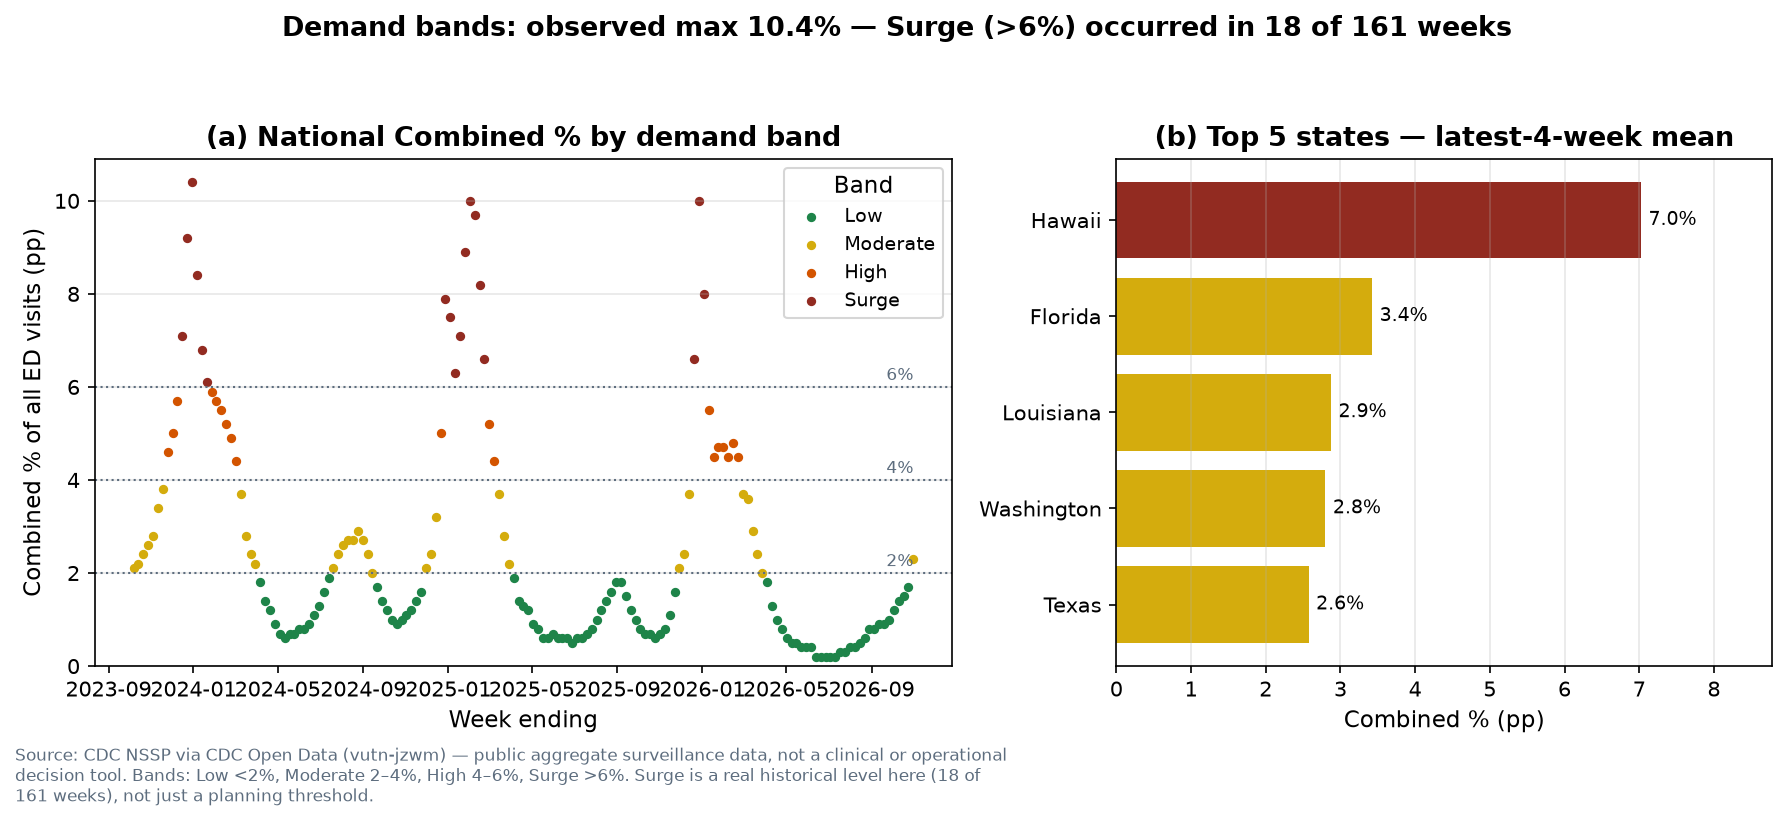

In [6]:
counts = record["forecast"]["band_counts_history"]
print(f"Historical band occurrence (161 weeks): {counts}")
print(f"Forecast bands: {list(forecast['band'])}")
recent = states[states["week_end"] > states["week_end"].max() - pd.Timedelta(weeks=4)]
top5 = recent.groupby("geography")["combined_pct"].mean().sort_values(ascending=False).head(5)
print("\nTop-5 states, latest-4-week mean Combined %:")
print(top5.round(2).to_string())
print("\nStaffing scenario (PLANNING ASSUMPTIONS — not measured data):")
for band, (posture, uplift) in {
    "Low": ("Baseline roster", "—"),
    "Moderate": ("Baseline staffing (monitor)", "—"),
    "High": ("+10% rostered shifts", "+10%"),
    "Surge": ("+25% rostered shifts + elective-deferral trigger", "+25%"),
}.items():
    print(f"  {band:9s} {posture:45s} {uplift}")
from IPython.display import Image, display

display(Image(str(ROOT / "outputs" / "charts" / "03_demand_bands.png")))


In [7]:
"""SQL check (plan §4.7): the same question in pandas and in SQL.

Mean Combined % by season, plus the 4-week lagged Combined % as a lag
feature — computed once in pandas, once in an in-memory SQLite database,
asserted equal.
"""
import sqlite3

pandas_means = national.groupby("season")["combined_pct"].mean().round(4)
national["lag_4w"] = national["combined_pct"].shift(4)
pandas_lag = national["lag_4w"].dropna().round(4).tolist()

conn = sqlite3.connect(":memory:")
national.to_sql("weekly", conn, index=False)
sql_means = dict(
    conn.execute(
        "SELECT season, ROUND(AVG(combined_pct), 4) FROM weekly GROUP BY season"
    ).fetchall()
)
for season, value in pandas_means.items():
    assert abs(sql_means[season] - value) < 1e-4, (season, sql_means[season], value)
sql_lag = [
    round(row[0], 4)
    for row in conn.execute(
        "SELECT combined_pct FROM weekly ORDER BY week_end LIMIT 157"
    ).fetchall()
]
assert sql_lag == pandas_lag, "4-week lag differs between SQL and pandas"
conn.close()
print("SQL == pandas: seasonal means", {k: round(v, 2) for k, v in pandas_means.items()})
print(f"SQL == pandas: 4-week lag feature matches on all {len(pandas_lag)} values")


SQL == pandas: seasonal means {'Autumn': 1.61, 'Spring': 1.74, 'Summer': 1.08, 'Winter': 6.22}
SQL == pandas: 4-week lag feature matches on all 157 values


In [8]:
"""Band-reachability check (plan §4.5): is Surge a real level or decorative?"""
observed_max = float(national["combined_pct"].max())
max_week = national.loc[national["combined_pct"].idxmax(), "week_end"].date()
counts = bands["band"].value_counts().to_dict()
print(f"Observed max Combined: {observed_max:.1f}% ({max_week})")
print(f"Historical band counts (161 weeks): Low {counts.get('Low', 0)}, "
      f"Moderate {counts.get('Moderate', 0)}, High {counts.get('High', 0)}, "
      f"Surge {counts.get('Surge', 0)}")
surge_weeks = bands[bands["band"] == "Surge"]["week_end"].dt.date.tolist()
print(f"Surge (>6%) occurred in {counts.get('Surge', 0)} weeks — most recent: {max(surge_weeks)}")
assert counts.get("Surge", 0) > 0, "Surge never occurred: bands would be decorative"
print("Verdict: Surge is reachable — the band is retained as observed, not re-cut.")


Observed max Combined: 10.4% (2023-12-30)
Historical band counts (161 weeks): Low 89, Moderate 35, High 19, Surge 18
Surge (>6%) occurred in 18 weeks — most recent: 2026-01-03
Verdict: Surge is reachable — the band is retained as observed, not re-cut.


In [9]:
"""Guarded forecast re-run (plan §6): only when the raw JSONs are present.

If the raw data was downloaded at build time, re-run the forecast from
src.forecast and assert the metrics match the committed backtest.csv /
forecast.csv within tolerance. Otherwise load the committed CSVs (already
loaded above) and note that the re-run was skipped — either way, 0 errors.
"""
from src import forecast as forecast_mod

raw_nssp = ROOT / "data" / "raw" / "nssp_ed_visits.json"
raw_bed = ROOT / "data" / "raw" / "bed_capacity.json"
if raw_nssp.exists() and raw_bed.exists():
    summary = forecast_mod.build_forecast(
        national["combined_pct"], national["week_end"], PROCESSED
    )
    committed = pd.read_csv(PROCESSED / "forecast.csv")
    assert summary["published_method"] == record["forecast"]["published_method"]
    for got, want in zip(summary["forecast_values"], committed["forecast_pct"]):
        assert abs(got - want) < 0.02, (got, want)
    print("Guarded re-run: forecast reproduced from raw data; "
          f"published method {summary['published_method']}, "
          f"mean RMSE HW {summary['mean_rmse']['holt_winters']:.4f} vs naive "
          f"{summary['mean_rmse']['seasonal_naive']:.4f} — matches committed CSVs.")
else:
    print("Raw JSONs not present (git-ignored, downloaded at build time) — "
          "forecast re-run skipped; committed forecast.csv loaded instead:")
    print(forecast[["week_end", "forecast_pct", "lo_80", "hi_80", "band"]].to_string(index=False))


Raw JSONs not present (git-ignored, downloaded at build time) — forecast re-run skipped; committed forecast.csv loaded instead:
  week_end  forecast_pct  lo_80  hi_80     band
2026-11-07          3.03   2.73   3.36 Moderate
2026-11-14          3.79   3.33   4.26 Moderate
2026-11-21          4.75   4.21   5.34     High
2026-11-28          5.68   5.00   6.35     High
2026-12-05          6.57   5.68   7.31    Surge
2026-12-12          8.19   7.23   9.07    Surge
2026-12-19         10.91   9.86  11.86    Surge
2026-12-26         13.87  12.76  14.91    Surge


Bed utilisation: mean 72.5%, max 78.9% (2022-12-10), latest 75.0% (2024-04-27)
Adult ICU occupancy: mean 72.5%, latest 71.7%
Weeks with <50 states reporting: 45 of 226 (all in 2020 — thin early reporting; the 2020 segment's 48.9–59.8% readings reflect 3–38 states, not the nation)
Full-coverage state-days in the sums: 86.36% (11,145 dropped)


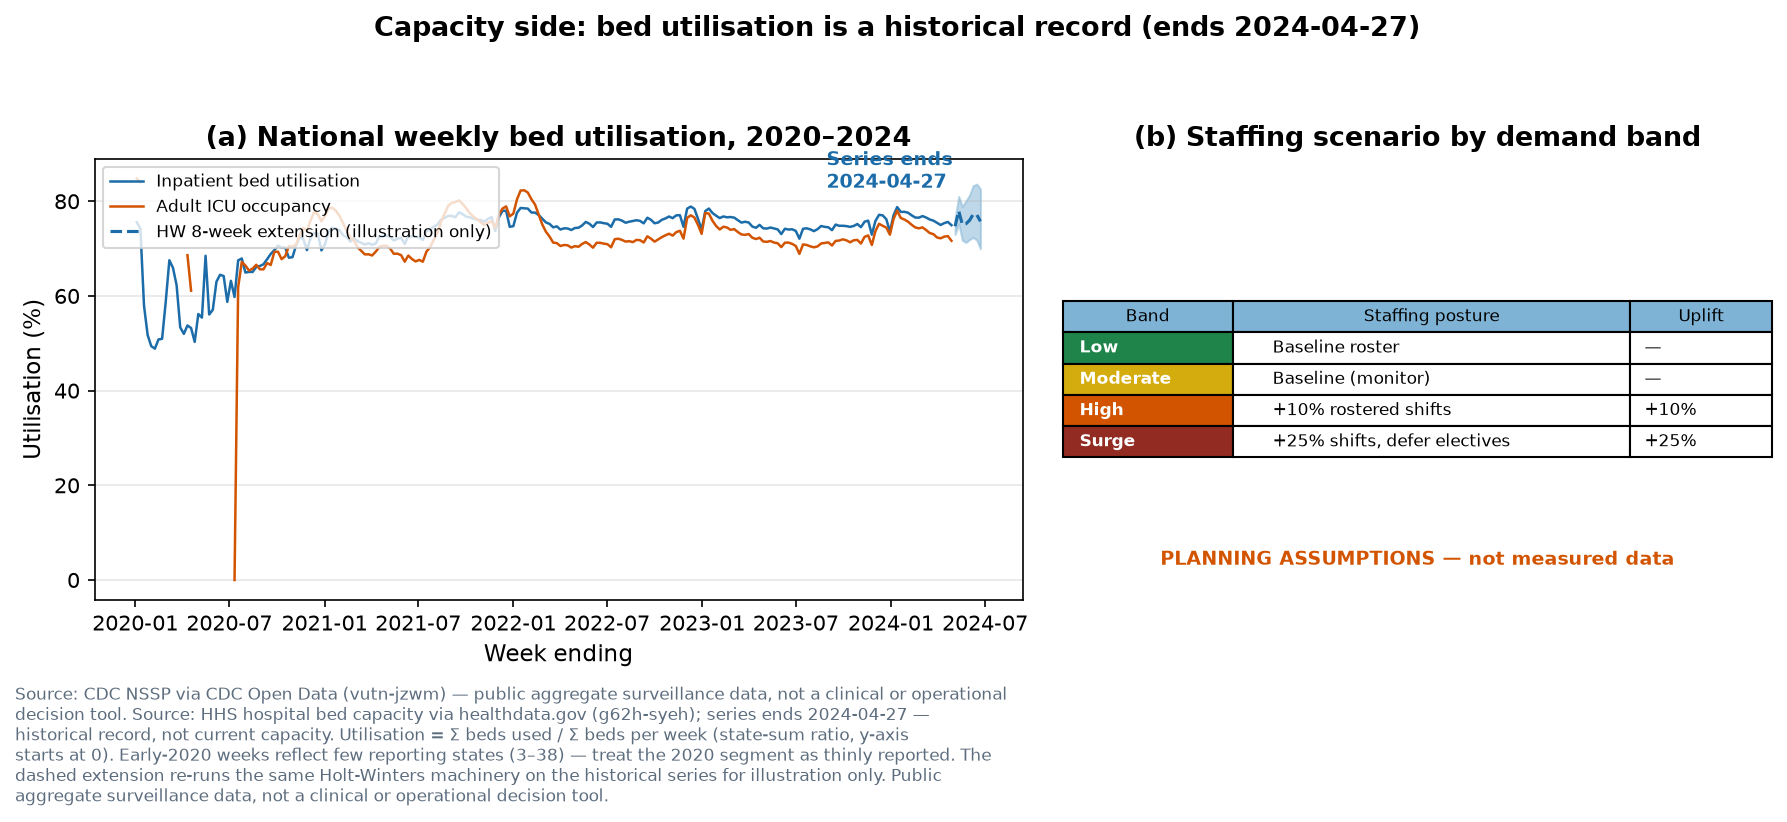

In [10]:
print(f"Bed utilisation: mean {bed['bed_utilisation'].mean() * 100:.1f}%, "
      f"max {bed['bed_utilisation'].max() * 100:.1f}% "
      f"({bed.loc[bed['bed_utilisation'].idxmax(), 'week_end'].date()}), "
      f"latest {bed['bed_utilisation'].iloc[-1] * 100:.1f}% "
      f"({bed['week_end'].iloc[-1].date()})")
print(f"Adult ICU occupancy: mean {bed['icu_occupancy'].mean() * 100:.1f}%, "
      f"latest {bed['icu_occupancy'].iloc[-1] * 100:.1f}%")
print(f"Weeks with <50 states reporting: {(bed['states_reporting'] < 50).sum()} of {len(bed)} "
      f"(all in 2020 — thin early reporting; the 2020 segment's 48.9–59.8% readings "
      f"reflect 3–38 states, not the nation)")
print(f"Full-coverage state-days in the sums: "
      f"{record['bed_coverage']['full_coverage_share'] * 100:.2f}% "
      f"({record['bed_coverage']['state_days_dropped']:,} dropped)")
from IPython.display import Image, display

display(Image(str(ROOT / "outputs" / "charts" / "04_bed_capacity.png")))


## Limitations and conclusion

- **The forecast's outer weeks exceed history.** The 8-week Holt-Winters forecast reaches 13.87%, above the observed maximum of 10.4%. The method is fixed by the plan (additive trend + additive seasonality, period 52, no tuning), and it wins the backtest — but an additive trend extrapolates the autumn rise without a ceiling. Read weeks 7–8 as a severe-season scenario.
- **A share, not a count.** The ED series is a percentage of all ED visits. Visit and admission numbers come only from the dashboard's volume converter, whose inputs (1,000 visits/week, 15% admission rate) are labelled planning assumptions.
- **Coverage is imperfect.** Holt-Winters' 80% intervals covered 75% of held-out actuals on average — close to target, but slightly narrow at one origin. MAPE (mean 42.19%) inflates in low summer weeks; RMSE is the honest comparator.
- **Beds are history, not now.** The bed series ends 2024-04-27; early-2020 weeks cover as few as 3 states. The dashed 8-week extension in chart 04 is a method illustration, not a capacity prediction.
- **Reporting gaps are recent.** Iowa has reported nothing since 2026-07-04 and Delaware/Georgia nothing since 2026-10-17. The national series is unaffected, but state comparisons for those three states stop at their last reported week.
- **Fitting note.** statsmodels' Holt-Winters optimiser emits a ConvergenceWarning on some windows (it stops on tolerance, not on a failed fit); the fitted parameters are finite and the forecasts sane, so the warning is suppressed in `src/forecast.py` and recorded here and in `data/README.md`.

**Bottom line:** respiratory demand is entering its winter climb from a hotter start than last year (flu 1.7% vs 0.3% a year ago). The honest forecast is Moderate demand for two weeks, High for two, then Surge posture for the final four — with the outer weeks flagged as exceeding anything observed in 2023–2026.
